[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcostac/generative-networks/blob/main/flows/flow_matching.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Training a Flow Matching Model on MNIST

Tutorial for training a small flow matching model to generate MNIST-like handwritten digits.

Flow matching learns a time-dependent vector field `v_theta(x_t, t)` that transports simple noise into data. Instead of learning an invertible architecture with exact log-determinants, we train a neural network to predict the velocity along paths between noise samples and real images.

In this notebook we use a rectified-flow setup:

- Sample noise `x0` from a standard normal distribution.
- Sample a data image `x1` from MNIST.
- Choose a random time `t` between 0 and 1.
- Interpolate `x_t = (1 - t) x0 + t x1`.
- Train the network to predict the velocity `x1 - x0`.

## 0. Dependencies

In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

The defaults are small enough for a tutorial. More epochs and more sampling steps usually improve generated digits.

In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "flows" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "flows" / "outputs" / "mnist_flow_matching"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
image_channels = 1
image_size = 28
image_dim = image_channels * image_size * image_size
hidden_dim = 512
time_embedding_dim = 64
epochs = 20
learning_rate = 2e-4
sample_steps = 100

sample_every_epochs = 5
checkpoint_path = output_dir / "mnist_flow_matching_checkpoint.pt"

## 3. Load MNIST

For flow matching we train in the image range `[-1, 1]`. This makes the data scale closer to the standard normal noise that starts the generative process.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), # Convert PIL image to tensor and scale pixel values to [0, 1].
    transforms.Normalize(mean=(0.5,), std=(0.5,)), # Scale pixel values to [-1, 1].
])

train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

len(train_dataset), len(train_loader), len(test_dataset), len(test_loader)

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(60000, 469, 10000, 79)

Let's inspect a batch of real MNIST images.

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


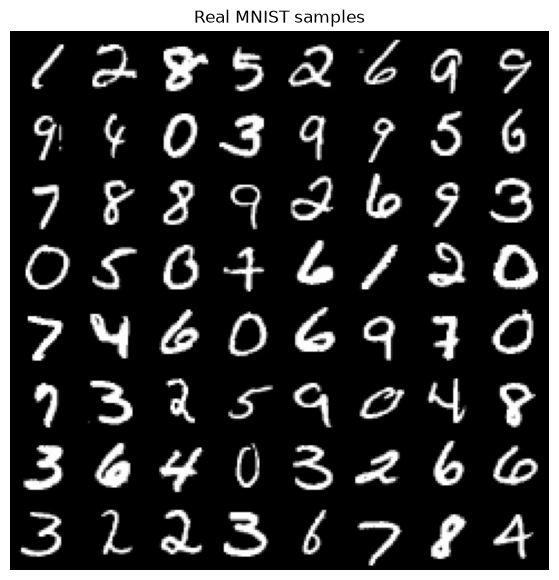

In [5]:
def denormalize(images):
    return (images + 1) / 2


def show_image_grid(images, title=None, nrow=8):
    images = denormalize(images.detach().cpu()).clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


real_images, real_labels = next(iter(train_loader))
show_image_grid(real_images[:64], title="Real MNIST samples")

## 4. Build Training Pairs

Flow matching uses supervised regression targets that we can construct from noise and data.

For each image `x1`, we sample a noise image `x0` and a random time `t`. The point at time `t` is a linear interpolation, and the target velocity is the constant direction from `x0` to `x1`.

In [6]:
def sample_flow_matching_batch(images):
    x1 = images.view(images.size(0), -1)
    x0 = torch.randn_like(x1)
    t = torch.rand(images.size(0), 1, device=images.device)
    xt = (1 - t) * x0 + t * x1
    target_velocity = x1 - x0
    return xt, t, target_velocity

## 5. Time Embeddings

The velocity field needs to know which time `t` it is seeing. We use sinusoidal features, similar to positional embeddings, then feed them to the MLP.

In [7]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, t):
        half_dim = self.embedding_dim // 2
        frequencies = torch.exp(
            -math.log(10000) * torch.arange(half_dim, device=t.device) / max(half_dim - 1, 1)
        )
        angles = t * frequencies.view(1, -1)
        embedding = torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)
        if self.embedding_dim % 2 == 1:
            embedding = F.pad(embedding, (0, 1))
        return embedding

## 6. Define the Velocity Network

This model receives a noised/interpolated image `x_t` and a time `t`, then predicts a velocity vector with the same shape as the flattened image.

In [8]:
class FlowMatchingMLP(nn.Module):
    def __init__(self, image_dim=784, hidden_dim=512, time_embedding_dim=64):
        super().__init__()
        self.time_embedding = SinusoidalTimeEmbedding(time_embedding_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(time_embedding_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.net = nn.Sequential(
            nn.Linear(image_dim + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, image_dim),
        )

    def forward(self, x, t):
        t_features = self.time_mlp(self.time_embedding(t))
        return self.net(torch.cat([x, t_features], dim=1))

## 7. Initialize Model and Optimizer

In [9]:
model = FlowMatchingMLP(image_dim, hidden_dim, time_embedding_dim).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

fixed_noise = torch.randn(64, image_dim, device=device)

print(model)

FlowMatchingMLP(
  (time_embedding): SinusoidalTimeEmbedding()
  (time_mlp): Sequential(
    (0): Linear(in_features=64, out_features=512, bias=True)
    (1): SiLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
  )
  (net): Sequential(
    (0): Linear(in_features=1296, out_features=512, bias=True)
    (1): SiLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): SiLU()
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): SiLU()
    (6): Linear(in_features=512, out_features=784, bias=True)
  )
)


## 8. Sampling and Checkpoint Helpers

To generate samples, start at Gaussian noise and integrate the learned velocity field from `t = 0` to `t = 1` using Euler steps.

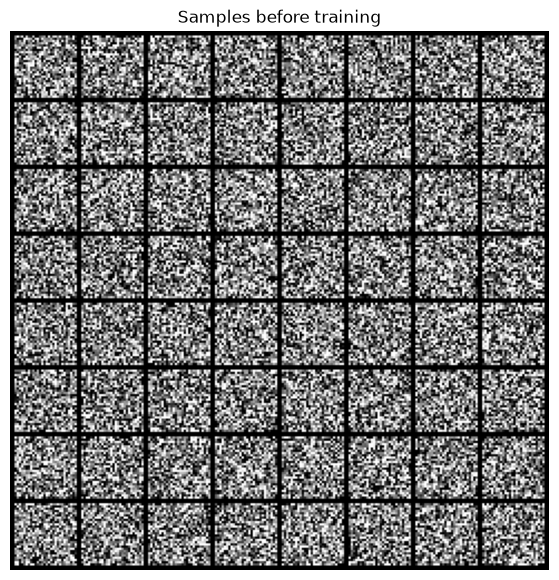

In [10]:
@torch.no_grad()
def generate_samples(model, noise=fixed_noise, steps=sample_steps):
    model.eval()
    x = noise.clone()
    dt = 1.0 / steps

    for step in range(steps):
        t_value = step / steps
        t = torch.full((x.size(0), 1), t_value, device=x.device)
        velocity = model(x, t)
        x = x + dt * velocity

    return x.view(-1, image_channels, image_size, image_size)


@torch.no_grad()
def sample_images(model, noise=fixed_noise, title="Generated samples", save_path=None):
    images = generate_samples(model, noise=noise)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(denormalize(images.cpu()).clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(images, title=title, nrow=8)


def save_checkpoint(epoch, history):
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "config": {
                "image_channels": image_channels,
                "image_size": image_size,
                "hidden_dim": hidden_dim,
                "time_embedding_dim": time_embedding_dim,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
                "sample_steps": sample_steps,
            },
        },
        checkpoint_path,
    )


sample_images(model, title="Samples before training")

Before training, the vector field is random, so integrating it does not produce meaningful digits.

## 9. Flow Matching Training Step

This objective is plain mean squared error between the predicted velocity and the target velocity. There is no discriminator, no variational bound, and no log-determinant.

In [11]:
def run_epoch(model, data_loader, train=True):
    model.train(train)
    total_loss = 0.0
    total_images = 0

    for images, _ in data_loader:
        images = images.to(device, non_blocking=True)
        xt, t, target_velocity = sample_flow_matching_batch(images)

        if train:
            optimizer.zero_grad(set_to_none=True)

        predicted_velocity = model(xt, t)
        loss = F.mse_loss(predicted_velocity, target_velocity)

        if train:
            loss.backward()
            optimizer.step()

        batch_size_seen = images.size(0)
        total_loss += loss.item() * batch_size_seen
        total_images += batch_size_seen

    return total_loss / total_images


def train_one_epoch(epoch, model, train_loader, test_loader):
    train_loss = run_epoch(model, train_loader, train=True)
    with torch.no_grad():
        test_loss = run_epoch(model, test_loader, train=False)

    return {
        "epoch": epoch,
        "train_loss": train_loss,
        "test_loss": test_loss,
    }

## 10. Train the Flow Matching Model

Run this cell to train. The loss measures velocity prediction error; generated sample quality is the most important qualitative check.

Epoch 001/020 | train loss: 1.24669 | test loss: 1.19042
Epoch 002/020 | train loss: 1.17556 | test loss: 1.15601
Epoch 003/020 | train loss: 1.14270 | test loss: 1.12696
Epoch 004/020 | train loss: 1.11251 | test loss: 1.09907
Epoch 005/020 | train loss: 1.09029 | test loss: 1.07946


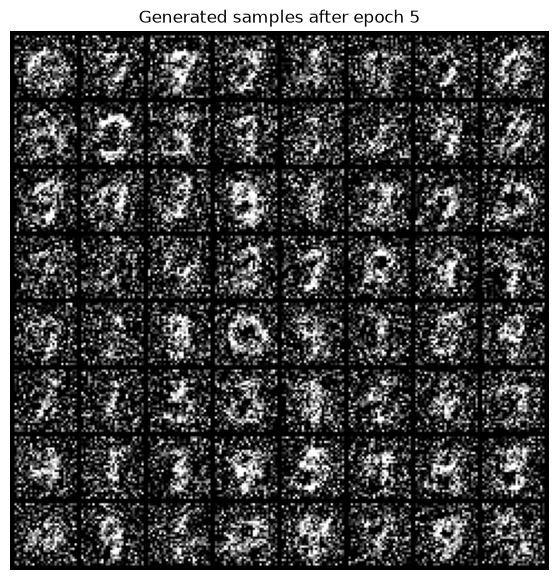

Epoch 006/020 | train loss: 1.07169 | test loss: 1.06217
Epoch 007/020 | train loss: 1.05604 | test loss: 1.04844
Epoch 008/020 | train loss: 1.04421 | test loss: 1.03571
Epoch 009/020 | train loss: 1.03390 | test loss: 1.02600
Epoch 010/020 | train loss: 1.02361 | test loss: 1.01770


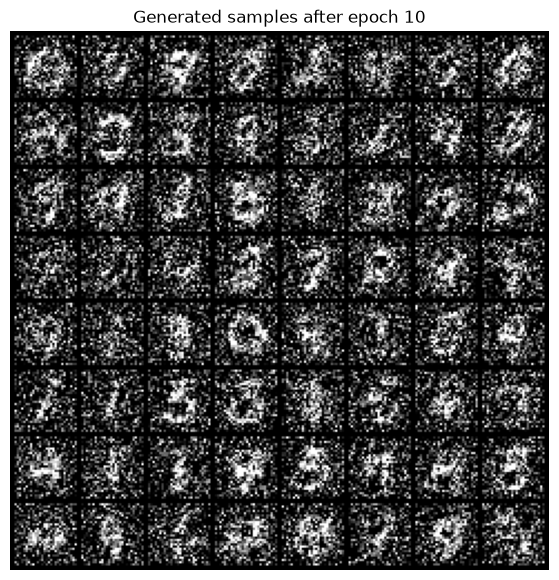

Epoch 011/020 | train loss: 1.01514 | test loss: 1.00873
Epoch 012/020 | train loss: 1.00778 | test loss: 1.00388
Epoch 013/020 | train loss: 1.00058 | test loss: 0.99640
Epoch 014/020 | train loss: 0.99381 | test loss: 0.99086
Epoch 015/020 | train loss: 0.98898 | test loss: 0.98428


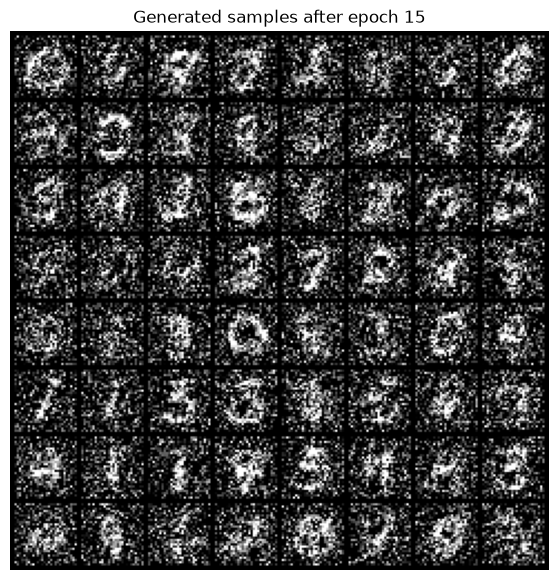

Epoch 016/020 | train loss: 0.98362 | test loss: 0.98142
Epoch 017/020 | train loss: 0.97930 | test loss: 0.97621
Epoch 018/020 | train loss: 0.97564 | test loss: 0.97056
Epoch 019/020 | train loss: 0.97132 | test loss: 0.96729
Epoch 020/020 | train loss: 0.96757 | test loss: 0.96516


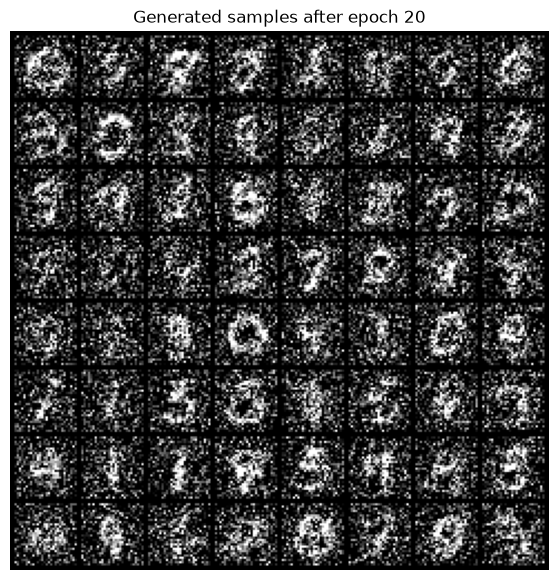

Saved latest checkpoint to: /home/nahuel/generative-networks/flows/outputs/mnist_flow_matching/mnist_flow_matching_checkpoint.pt


In [12]:
history = []

for epoch in range(1, epochs + 1):
    metrics = train_one_epoch(epoch, model, train_loader, test_loader)
    history.append(metrics)

    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"train loss: {metrics['train_loss']:.5f} | "
        f"test loss: {metrics['test_loss']:.5f}"
    )

    if epoch % sample_every_epochs == 0 or epoch == epochs:
        sample_path = output_dir / f"samples_epoch_{epoch:03d}.png"
        sample_images(model, title=f"Generated samples after epoch {epoch}", save_path=sample_path)

    save_checkpoint(epoch, history)

print(f"Saved latest checkpoint to: {checkpoint_path}")

## 11. Plot Training Curves

The flow matching loss is a regression loss, so unlike GAN losses it is straightforward to monitor. Lower is usually better, though samples are still the final check.

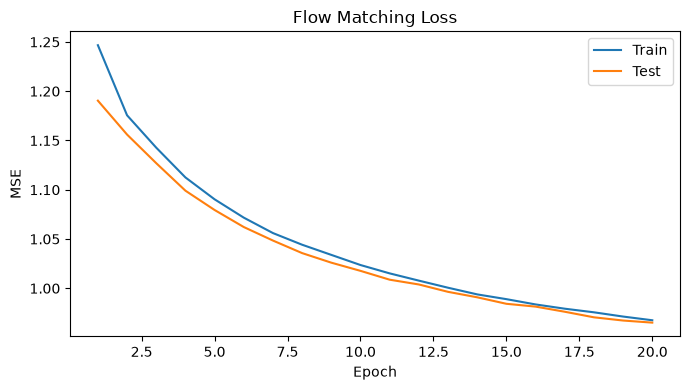

In [18]:
epochs_seen = [row["epoch"] for row in history]

plt.figure(figsize=(7, 4))
plt.plot(epochs_seen, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.title("Flow Matching Loss")
plt.tight_layout()
plt.show()

## 12. Generate New Digits

Draw fresh Gaussian noise and integrate the learned vector field forward in time.

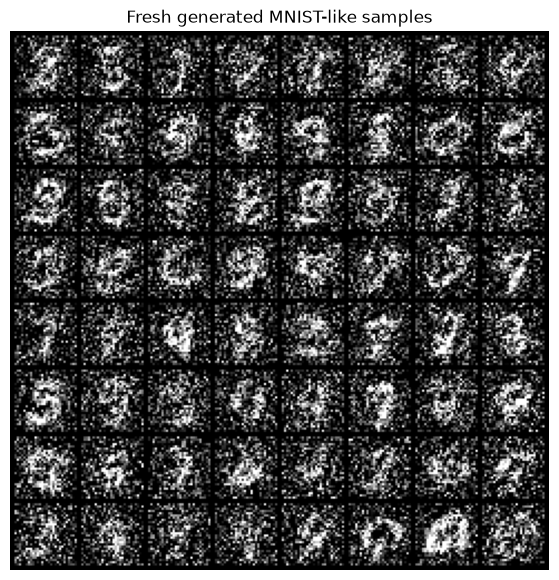

In [19]:
new_noise = torch.randn(64, image_dim, device=device)
sample_images(model, noise=new_noise, title="Fresh generated MNIST-like samples")

## 13. Visualize the Sampling Trajectory

This cell saves a few intermediate states while integrating from noise to data. Early images should look noisy; later images should become more digit-like.

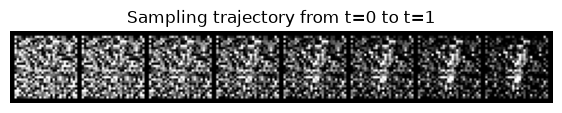

In [20]:
@torch.no_grad()
def show_sampling_trajectory(model, steps=sample_steps, snapshots=8):
    model.eval()
    x = torch.randn(1, image_dim, device=device)
    dt = 1.0 / steps
    snapshot_steps = torch.linspace(0, steps, snapshots).long().tolist()
    images = []

    for step in range(steps + 1):
        if step in snapshot_steps:
            images.append(x.view(1, image_channels, image_size, image_size).detach().clone())
        if step == steps:
            break
        t = torch.full((x.size(0), 1), step / steps, device=x.device)
        velocity = model(x, t)
        x = x + dt * velocity

    images = torch.cat(images, dim=0)
    show_image_grid(images, title="Sampling trajectory from t=0 to t=1", nrow=snapshots)


show_sampling_trajectory(model)

## 14. Latent Noise Interpolation

Interpolate between two initial noise vectors, then integrate each point along the learned flow. Smooth changes suggest that the model learned a coherent transport map.

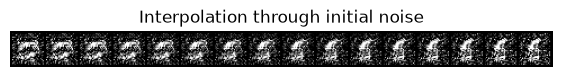

In [21]:
@torch.no_grad()
def interpolate_initial_noise(model, steps=16):
    z_start = torch.randn(1, image_dim, device=device)
    z_end = torch.randn(1, image_dim, device=device)
    weights = torch.linspace(0, 1, steps, device=device).view(steps, 1)
    noise = (1 - weights) * z_start + weights * z_end
    images = generate_samples(model, noise=noise)
    show_image_grid(images, title="Interpolation through initial noise", nrow=steps)


interpolate_initial_noise(model)

## 15. Loading a Saved Checkpoint

Use this cell later if you restart the kernel and want to resume from the latest saved model.

In [17]:
# checkpoint = torch.load(checkpoint_path, map_location=device)
# model.load_state_dict(checkpoint["model_state_dict"])
# optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# history = checkpoint["history"]
# print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")

## 16. Things to Try

- Increase `sample_steps` and compare sample quality with generation speed.
- Train longer and compare samples against the normalizing flow notebook.
- Replace the MLP with a small U-Net or convolutional network.
- Use a nonlinear probability path instead of straight-line interpolation.
- Try classifier-free conditioning by feeding digit labels into the velocity network.

## Troubleshooting

- If samples are noisy, train longer, increase `hidden_dim`, or use more sampling steps.
- If sampling is slow, reduce `sample_steps` while experimenting.
- If you run out of GPU memory, lower `batch_size` or `hidden_dim`.